In [2]:
from dotenv import load_dotenv
import os

load_dotenv()

# print("OPENAI_API_KEY:", os.getenv("OPENAI_API_KEY"))

True

In [3]:
from langchain_openai import OpenAIEmbeddings

emb = OpenAIEmbeddings(model="text-embedding-3-small")


In [4]:
text1 = "Erreur lors du chargement du tableau de bord"
text2 = "Le tableau de bord ne s'affiche pas"
text3 = "Le client a commandé un nouveau serveur"

In [5]:
v1 = emb.embed_query(text1)
v2 = emb.embed_query(text2)
v3 = emb.embed_query(text3)

In [6]:
import numpy as np
def cosine_similarity(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

In [7]:
from sklearn.metrics.pairwise import cosine_similarity as cos
cos ([v1], [v2]) [0][0]

np.float64(0.7759050442218045)

In [8]:
print("Sim(text1, text2) =", cos([v1], [v2])[0][0])
print("Sim(text1, text3) =", cos([v1], [v3])[0][0])
print("Sim(text2, text3) =", cos([v2], [v3])[0][0])

Sim(text1, text2) = 0.7759050442218045
Sim(text1, text3) = 0.2926084926730149
Sim(text2, text3) = 0.2539397007475729


In [9]:
sentences = [
    "Erreur lors du chargement du tableau de bord.",
    "Le tableau de bord ne s'affiche pas.",
    "Impossible de se connecter à l'API.",
    "Problème d'authentification sur le service.",
    "Le client a commandé un nouveau serveur.",
    "Livraison prévue pour la semaine prochaine.",
    "Le serveur physique est tombé en panne.",
    "Mise à jour réussie du système."
]

In [10]:
vectors = [emb.embed_query(sentence) for sentence in sentences]

In [11]:
from sklearn.manifold import TSNE
import numpy as np
   
vectors_np = np.array(vectors)
tsne = TSNE(n_components=2, perplexity=5, random_state=2)
points_tsne = tsne.fit_transform(vectors_np)

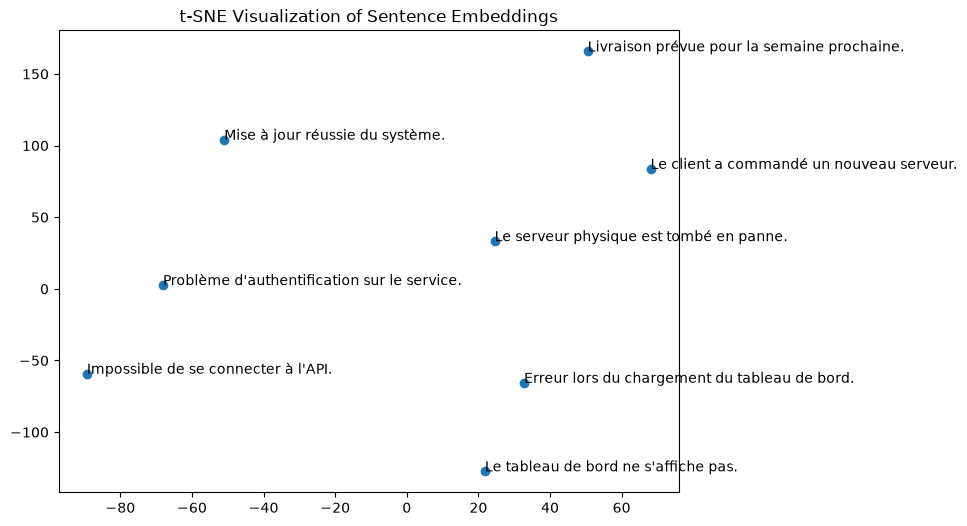

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(points_tsne[:, 0], points_tsne[:, 1])

for i, txt in enumerate(sentences):
    plt.annotate(txt, (points_tsne[i, 0], points_tsne[i, 1]))
    
plt.title("t-SNE Visualization of Sentence Embeddings")
plt.show()

d:\Data\study\INSTA\M2\ia_generative\rag_project1\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
d:\Data\study\INSTA\M2\ia_generative\rag_project1\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
d:\Data\study\INSTA\M2\ia_generative\rag_project1\.venv\Lib\site-packages\umap\umap_.py:2462: UserWarning: n_neighbors is larger than the dataset size; truncating to X.shape[0] - 1
  warn(


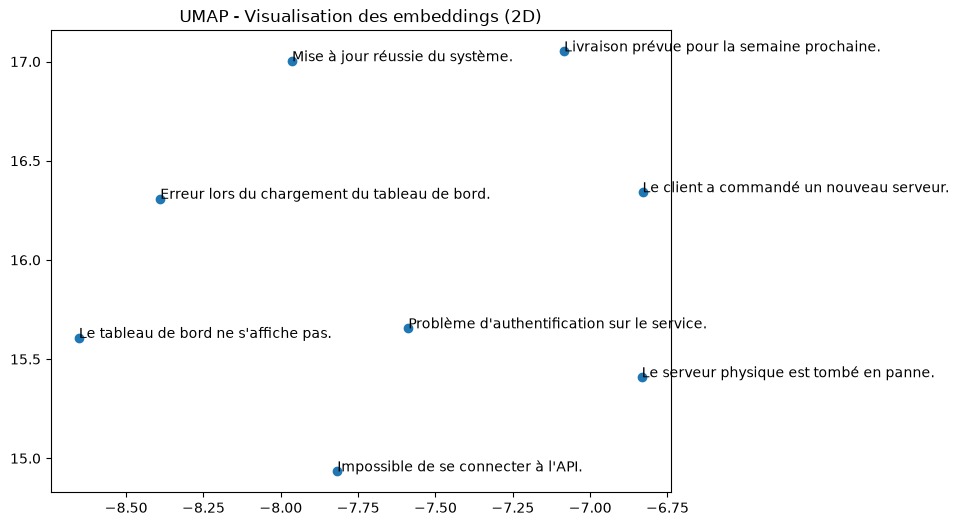

In [13]:
import umap
   
reducer = umap.UMAP(n_components=2, random_state=42)
points_umap = reducer.fit_transform(vectors)
   
plt.figure(figsize=(8,6))
plt.scatter(points_umap[:,0], points_umap[:,1])
   
for i, txt in enumerate(sentences):
        plt.annotate(txt, (points_umap[i,0], points_umap[i,1]))
   
plt.title("UMAP - Visualisation des embeddings (2D)")
plt.show()

In [14]:
# Charger un modèle local - all-MiniLM-L6-v2
   
from sentence_transformers import SentenceTransformer
model_local = SentenceTransformer("all-MiniLM-L6-v2")

text1_local = "le tableau de bord ne se charge plus."
vec_local = model_local.encode(text1_local)
vec_local[:10]


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2683.93it/s]


array([-0.03184031,  0.01374888, -0.02832196, -0.08591655,  0.03002452,
        0.01863885,  0.06294079,  0.07556867,  0.02374175,  0.04800685],
      dtype=float32)

In [ ]:
sentences = [
        "Erreur lors du chargement du tableau de bord.",
       "Le tableau de bord ne s'affiche pas.",
       "Le client a commandé un nouveau serveur."
    ]
vecs = model_local.encode(sentences)
vecs

array([[-0.04345766,  0.00539028, -0.00838225, ...,  0.01735133,
         0.05067737,  0.00742124],
       [ 0.00170493, -0.0107273 , -0.03334428, ...,  0.06998381,
         0.06510029, -0.0278607 ],
       [-0.06412877,  0.06582989, -0.03678605, ...,  0.07270839,
        -0.02667797,  0.04518537]], shape=(3, 384), dtype=float32)

Document loading

In [16]:
import os
   
docs_directory = "../data/text_files"
raw_docs = []
filenames = []
metadatas = []
   
for filename in os.listdir(docs_directory):
        if filename.endswith(".txt"):
            path = os.path.join(docs_directory, filename)
            with open(path, "r", encoding='utf-8') as f :
                text = f.read()
                raw_docs.append(text)
                filenames.append(filename)
                metadatas.append({"source":filename})

In [17]:
from langchain_text_splitters import RecursiveCharacterTextSplitter
   
splitter = RecursiveCharacterTextSplitter(
        chunk_size = 600,
        chunk_overlap = 80,
        separators=["\n\n", "\n", ".", " ", ""]
    )

all_chunks = splitter.create_documents(raw_docs, metadatas=metadatas)
print(len(all_chunks))
print(all_chunks[0].page_content)

25
Incident Report — API Gateway Failure  
Date : 2024-01-12  
Client : TechVision  
Rédacteur : Équipe SRE / Support Niveau 2  

Résumé exécutif  
À 09:14, plusieurs services critiques ont commencé à remonter des erreurs liées à l’API Gateway.  
Entre 09:14 et 09:52, le trafic entrant a été fortement perturbé, entraînant une indisponibilité partielle des services dépendants : authentification, reporting analytique, synchronisation CRM, gestion des comptes utilisateurs.


Embedding(génération des vecteurs)

In [18]:
from langchain_openai import OpenAIEmbeddings

# Charger ta clé API depuis le .env
import os
from dotenv import load_dotenv
 
load_dotenv()
   
os.getenv("OPENAI_API_KEY")[:10] + "..."

'sk-proj-FA...'

In [19]:
# Initialiser le modèle d’embeddings
emb = OpenAIEmbeddings(model="text-embedding-3-small")

In [20]:
# Générer tes premiers embeddings
sample_vector = emb.embed_query(all_chunks[0].page_content)
print(len(sample_vector))

1536


In [21]:
from langchain_chroma import Chroma
 
from langchain_core.documents import Document

In [22]:
documents = []

for chunk, meta in zip(all_chunks, metadatas):
    documents.append(Document(page_content=chunk.page_content, metadata={"source": meta["source"]}))

In [23]:
# Initialiser ChromaDB comme Vector Store
   
from langchain_community.vectorstores import Chroma
vector_store = Chroma(
        collection_name= "support_docs",
        embedding_function=emb,
        persist_directory="./vector_store"
    )

C:\Users\user\AppData\Local\Temp\ipykernel_21776\1481135889.py:3: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import Chroma
C:\Users\user\AppData\Local\Temp\ipykernel_21776\1481135889.py:4: LangChainDeprecationWarning: The class `Chroma` was deprecated in LangChain 0.2.9 and will be removed in 1.0. An updated version of the class exists in the `langchain-chroma package and should be used instead. To use it run `pip install -U `langchain-chroma` and import as `from `langchain_chroma import Chroma``.
  vector_store = Chroma(


In [24]:
vector_store.add_documents(documents)

['0bd9cbe6-ddf5-46f8-af63-0604976d1768',
 '28776c2c-671c-4b18-b86e-990a59e2d184',
 'a66d7caa-adcb-4c65-840b-e3b058d52ea3',
 '82298f84-ec5c-4cdf-91b3-38e7fc0804b3']

In [36]:
query = "Quelle est la cause des retards observés dans le tableau de bord Analytics ?"

In [37]:
results = vector_store.similarity_search("pourquoi le tableau de bord ne se charge plus.", k=3)
    

In [34]:
# Affichage des résultats
for i, doc in enumerate(results):
        print(f"\n--- RESULT {i+1} ---")
        print("Source :", doc.metadata.get("source")),
        print(doc.page_content[:300], "...")
        
 # Construire un contexte à partir des résultats Chroma
def build_context(docs) : 
        context = ""
        for doc in docs : 
            context  += f"Source :{doc.metadata.get('source')}\n"
            context += doc.page_content + "\n\n"
        return context
        
        
context = build_context(results)
print(context[:700]+"...")


--- RESULT 1 ---
Source : procedure_reset.txt
Contexte  
Depuis la mise en production de la version 3.14 du Gateway Manager, un mécanisme de répartition de charge dynamique a été introduit. Une surveillance renforcée était en cours, mais aucun symptôme anormal n’avait été observé avant l’incident. ...

--- RESULT 2 ---
Source : procedure_reset.txt
Contexte  
Depuis la mise en production de la version 3.14 du Gateway Manager, un mécanisme de répartition de charge dynamique a été introduit. Une surveillance renforcée était en cours, mais aucun symptôme anormal n’avait été observé avant l’incident. ...

--- RESULT 3 ---
Source : ticket_analytics.txt
Chronologie détaillée  
09:14 — Premiers signaux d’alerte (pics d’erreurs 502 et 504).  
09:17 — Les dashboards internes affichent un taux d’échec des requêtes supérieur à 85%.  
09:20 — Escalade automatique vers l’équipe SRE.  
09:27 — Analyse des logs : saturation du thread pool et accumulation de ...
Source :procedure_reset.txt
Contexte  


In [38]:
# Construire la question finale (Prompt Final)

final_prompt =  f"""
Tu es un assistant technique interne.
    Utilise UNIQUEMENT les informations du contexte ci-dessous pour répondre.
    Si l'information n'est pas présente , dis que tu ne sais pas.  
### CONTEXTE
    {context}

### QUESTION
    {query}

### REPONSE: 
    """
print(final_prompt[:700]+"...")


Tu es un assistant technique interne.
    Utilise UNIQUEMENT les informations du contexte ci-dessous pour répondre.
    Si l'information n'est pas présente , dis que tu ne sais pas.  
### CONTEXTE
    Source :procedure_reset.txt
Contexte  
Depuis la mise en production de la version 3.14 du Gateway Manager, un mécanisme de répartition de charge dynamique a été introduit. Une surveillance renforcée était en cours, mais aucun symptôme anormal n’avait été observé avant l’incident.

Source :procedure_reset.txt
Contexte  
Depuis la mise en production de la version 3.14 du Gateway Manager, un mécanisme de répartition de charge dynamique a été introduit. Une surveillance renforcée était en cours, m...


In [39]:
# Envoyer au modèle (OPENAI / GPT)
from openai import OpenAI
client = OpenAI()
    
response = client.chat.completions.create(
        model="gpt-4o-mini",
       messages=[
            {"role": "user", "content": final_prompt}
        ]
    )
print(response.choices[0].message.content)

La cause des retards observés dans le tableau de bord Analytics est la saturation du thread pool et l'accumulation de requêtes en attente, ainsi qu'un nœud du cluster API ne répondant plus.


In [40]:
# Question utilisateur
query = "Quelle est la cause des retards observés dans le tableau de bord Analytics ?"

In [41]:
 # Recherche avec scores
results_with_scores = vector_store.similarity_search_with_score(query, k=5)

In [42]:
# Afficher les résultats
for doc, score in results_with_scores:
        print("\nScore :", round(score, 3))
        print("Source :", doc.metadata.get("source"))
        print(doc.page_content[:200], "...") 


Score : 0.841
Source : ticket_analytics.txt
Impact métier  
- 432 utilisateurs affectés  
- 17 opérations critiques retardées  
- Indisponibilité complète du portail analytics pendant 38 minutes  
- Retard dans la synchronisation CRM (cycle de  ...

Score : 0.973
Source : ticket_analytics.txt
Chronologie détaillée  
09:14 — Premiers signaux d’alerte (pics d’erreurs 502 et 504).  
09:17 — Les dashboards internes affichent un taux d’échec des requêtes supérieur à 85%.  
09:20 — Escalade auto ...

Score : 0.973
Source : reglement.txt
Chronologie détaillée  
09:14 — Premiers signaux d’alerte (pics d’erreurs 502 et 504).  
09:17 — Les dashboards internes affichent un taux d’échec des requêtes supérieur à 85%.  
09:20 — Escalade auto ...

Score : 1.131
Source : incident_report.txt
Incident Report — API Gateway Failure  
Date : 2024-01-12  
Client : TechVision  
Rédacteur : Équipe SRE / Support Niveau 2  

Résumé exécutif  
À 09:14, plusieurs services critiques ont commencé à re ...

Score :

In [43]:
THRESHOLD = 1.05  # distance max acceptable
filtered_docs = [
        doc for doc, score in results_with_scores
       if score <= THRESHOLD
]


if not filtered_docs:
        print("Aucun document pertinent trouvé : le RAG doit répondre 'Je ne sais pas'.")
else:
        print(f"{len(filtered_docs)} document(s) pertinent(s) trouvé(s).")

3 document(s) pertinent(s) trouvé(s).


In [44]:
# Construire le contexte à partir des documents pertinents 
def build_context_from_docs(docs):
        context = ""
        for i, doc in enumerate(docs, start=1):
           source = doc.metadata.get("source", "inconnu")
           context += f"--- Document {i} (source : {source}) ---\n"
           context += doc.page_content.strip() + "\n\n"
        return context

In [45]:
# Construire le prompt final (LLM-ready)
def build_final_prompt(query: str, context: str) -> str:
        return f"""
    Tu es un assistant interne pour une équipe Data & Analytics.

    Tu dois répondre UNIQUEMENT à partir du contexte ci-dessous.
    Si la réponse ne se trouve pas dans le contexte, dis explicitement : 
    "Je ne sais pas, l'information n'est pas présente dans les documents."
### CONTEXTE
    {context}
    
    ### QUESTION UTILISATEUR
    {query}
    
    ### RÉPONSE ATTENDUE
    - Sois clair et concis.
    - Base-toi uniquement sur le contexte.
    - Si possible, résume en 3 à 5 phrases maximum.
    """

In [46]:
from openai import OpenAI
client = OpenAI()
if not filtered_docs:
        print("Aucun document suffisamment pertinent trouvé.")
        print("Réponse RAG : Je ne sais pas, l'information " \
        "n'est pas présente dans les documents.")
else:
       context = build_context_from_docs(filtered_docs)
       final_prompt = build_final_prompt(query, context)

       response = client.chat.completions.create(
            model="gpt-4o-mini",
            messages=[
               {"role": "user", "content": final_prompt}
           ]
       )
answer = response.choices[0].message.content
print("🔎 QUESTION :", query)
print("\n📄 CONTEXTE UTILISÉ :\n")
print(context[:800] + "...\n")
print("✅ RÉPONSE DU LLM :\n")
print(answer)

🔎 QUESTION : Quelle est la cause des retards observés dans le tableau de bord Analytics ?

📄 CONTEXTE UTILISÉ :

--- Document 1 (source : ticket_analytics.txt) ---
Impact métier  
- 432 utilisateurs affectés  
- 17 opérations critiques retardées  
- Indisponibilité complète du portail analytics pendant 38 minutes  
- Retard dans la synchronisation CRM (cycle de 10h)  
Aucun impact sur la facturation, mais deux clients ont ouvert un ticket prioritaire.

Analyse technique  
Les logs révèlent une dégradation progressive liée à :  
1. Une montée en charge inattendue provenant de scripts automatisés.  
2. Une configuration sous-optimale du pool de threads.  
3. Une fuite mémoire détectée sur le module de transformation JSON.

--- Document 2 (source : ticket_analytics.txt) ---
Chronologie détaillée  
09:14 — Premiers signaux d’alerte (pics d’erreurs 502 et 504).  
09:17 — Les dashboards internes affichent ...

✅ RÉPONSE DU LLM :

Les retards observés dans le tableau de bord Analytics sont pr